In [1]:
from time import time
import gc
# 安裝一次：pip install psutil
import psutil
import os
def print_memory_info():
    process = psutil.Process(os.getpid())
    rss_gb = process.memory_info().rss / (1024**3)
    vms_gb = process.memory_info().vms / (1024**3)
    print(f"當前 process 記憶體  RSS: {rss_gb:.2f} GB  虛擬 VMS: {vms_gb:.2f} GB")
process_start_time = time()
print_memory_info()


當前 process 記憶體  RSS: 0.06 GB  虛擬 VMS: 0.72 GB


In [2]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np


# Jupyter cwd 在 testing/ 時用 parent；否則用 cwd
_cwd = Path.cwd()
root = _cwd.parent if _cwd.name == "testing" else _cwd
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

# 把 qlib_source 放在最前面，讓 import qlib 載到它
qlib_root = root / "qlib_source"   # root 是上面算出來的專案根目錄
if str(qlib_root) not in sys.path:
    sys.path.insert(0, str(qlib_root))
print(f"Project root: {root}")

from src.factor_engine import FactorEngine

RAM_PATH="/dev/shm/qlib_ram"     # 改成你的實際路徑
start_time = "2000-01-01"
end_time = "2026-01-20"
engine = FactorEngine(
    qlib_data_path=RAM_PATH,
    instrument="all",
    start_time=start_time,
    end_time=end_time,
    device="cpu",               # 支援 "cpu" / "cuda:0" 字串或 torch.device
    max_backtrack_days=300,
    max_future_days=0,
    adjust_factor = 'back'
)
print_memory_info()

Project root: /home/newt/quant_project/src/factor
data path: /dev/shm/qlib_ram


[632550:MainThread](2026-02-17 22:03:02,088) INFO - qlib.Initialization - [config.py:452] - default_conf: client.
[632550:MainThread](2026-02-17 22:03:02,540) INFO - qlib.Initialization - [__init__.py:82] - qlib successfully initialized based on client settings.
[632550:MainThread](2026-02-17 22:03:02,541) INFO - qlib.Initialization - [__init__.py:84] - data_path={'__DEFAULT_FREQ': PosixPath('/dev/shm/qlib_ram')}


[FactorEngine] Loading data: instrument=all, period=[2000-01-01, 2026-01-20], device=cpu
[FactorEngine] Data loaded: 6141 days, 2352 stocks, 10 features, tensor shape=(6441, 10, 2352)
當前 process 記憶體  RSS: 1.76 GB  虛擬 VMS: 9.01 GB


In [3]:
from src.alphas.alpha101 import Alpha101
from src.alphas.alpha191 import Alpha191
feature_exprs = []  # 或你實際的因子表達式
feature_names = []
alpha101_all = Alpha101.get_all_factors()
alpha191_all = Alpha191.get_all_factors()
for name, expr in alpha101_all.items():
    feature_exprs.append(expr)
    feature_names.append(f'alpha101_{name}')
for name, expr in alpha191_all.items():
    feature_exprs.append(expr)
    feature_names.append(f'alpha191_{name}')
print(feature_exprs[:5])
print(feature_names[:5])    
print_memory_info()

['Sub(CSRank(Ts_ArgMax(SignedPower(If(Gt($return_day, 0), Std($return_day, 20), $close), 2), 5)), 0.5)', 'Mul(-1, Corr(CSRank(Delta(Log($volume), 2)), CSRank(Div(Sub($close, $open), $open)), 6))', 'Mul(-1, Corr(CSRank($open), CSRank($volume), 10))', 'Mul(-1, Ts_Rank(CSRank($low), 9))', 'Mul(CSRank(Sub($open, Mean(SafeDiv($amount, $volume), 10))), Mul(-1, Abs(CSRank(Sub($close, SafeDiv($amount, $volume))))))']
['alpha101_alpha001', 'alpha101_alpha002', 'alpha101_alpha003', 'alpha101_alpha004', 'alpha101_alpha005']
當前 process 記憶體  RSS: 1.76 GB  虛擬 VMS: 9.01 GB


In [4]:
# 假設你已有 engine，且 max_future_days >= 1
# 特徵（你已經算好的因子名列表）


# 特徵 DataFrame：index = (datetime, instrument), columns = feature_names
df_feature = engine.calc_many_df(feature_exprs, names=feature_names, normalize=False)
df_feature.columns = pd.MultiIndex.from_product([["feature"], df_feature.columns])
gc.collect()
df_feature.head()
print_memory_info()

當前 process 記憶體  RSS: 17.53 GB  虛擬 VMS: 24.77 GB


In [5]:
# # 標籤：例如未來 1 日報酬 Ref($close, -1)/$close - 1（需 max_future_days>=1）
# # 1/2 的因子 → 預測 1/3 買、1/4 賣的報酬 = close(1/4)/close(1/3) - 1
# 拉出 $close，得到 index=(datetime, instrument)、一欄 close
df_close = engine.calc_df("$close", col_name="close").sort_index()
label_series = (
    df_close
    .groupby(level="instrument", group_keys=False)
    .apply(lambda g: np.log(g["close"].shift(-2) / g["close"].shift(-1)))
    #.apply(lambda g: g["close"].shift(-2) / g["close"].shift(-1) - 1)
)
label_series = label_series.sort_index()
label_series.name = "LABEL0"
df_label = label_series.to_frame()
# 讓 df_label 和 df_feature 一樣是兩層 columns：(level0, level1)
# 先統一成一個欄位名（例如 return_1day），再包成 MultiIndex
if isinstance(df_label.columns, pd.MultiIndex):
    _names = df_label.columns.get_level_values(-1).unique().tolist()
else:
    _names = list(df_label.columns)

# 若你想把 "LABEL0" 當成 return_1day 來用，可先改欄位名再包
df_label = df_label.rename(columns={_names[0]: "return_1day"})
df_label.columns = pd.MultiIndex.from_tuples([("label", "return_1day")])
gc.collect()
print_memory_info()

當前 process 記憶體  RSS: 17.78 GB  虛擬 VMS: 25.03 GB


In [6]:
import pandas as pd

# 組成 qlib 格式：columns 第一層 = "feature" | "label"
# df_label.columns 可能是 Index 或 MultiIndex，先轉成 list 再組兩層，避免 from_product 對 MultiIndex 報錯
df_all = pd.concat([df_feature, df_label], axis=1).sort_index()
del df_feature ,df_label
gc.collect()
print_memory_info()
# 若有缺的 (date, instrument) 可再 reindex 或 dropna

當前 process 記憶體  RSS: 17.84 GB  虛擬 VMS: 25.08 GB


In [7]:
# %timeit
# %reload_ext autoreload
# %autoreload 2
from panda_factor.panda_factor.panda_factor.analysis.factor_func import ext_out_3std_list_vectorized
# 按「日」分組，每天對所有 feature 做 3-sigma + inf 處理（與 factor_test 同邏輯）
ext_out_3std_list_vectorized(
    df_all["feature"], factor_list=feature_names, process_inf=True
)
gc.collect()
print_memory_info()

2026-02-17 22:09:55 - panda_common.logger_config - INFO - 从配置文件加载配置: /home/newt/quant_project/panda_factor/panda_common/panda_common/config.yaml
2026-02-17 22:09:55 - panda_common.logger_config - INFO - 从环境变量更新配置: USER
2026-02-17 22:09:55 - panda_common.logger_config - INFO - 初始化配置成功: {'HUB_START_DATE': 20170101, 'HUB_END_DATE': 20250321, 'UPDATE_TIME': '20:00', 'STOCKS_UPDATE_TIME': '20:00', 'FACTOR_UPDATE_TIME': '20:30', 'DATASOURCE': 'tqsdk', 'DATAHUBSOURCE': '', 'MUSER': '', 'MPASSWORD': '', 'TS_TOKEN': '', 'XT_TOKEN': '', 'USER': 'newt', 'PASSWORD': 'xxxxxx', 'MONGO_USER': 'panda', 'MONGO_PASSWORD': 'panda', 'MONGO_URI': '127.0.0.1:27017', 'MONGO_AUTH_DB': 'admin', 'MONGO_DB': 'panda', 'MONGO_TYPE': 'replica_set', 'MONGO_REPLICA_SET': 'rs0', 'LLM_API_KEY': '这里填写你的KEY', 'LLM_MODEL': 'deepseek-chat', 'LLM_BASE_URL': 'https://api.deepseek.com/v1', 'LOG_LEVEL': 'DEBUG', 'log_file': 'logs/data_cleaner.log', 'log_rotation': '1 MB'}


當前 process 記憶體  RSS: 17.83 GB  虛擬 VMS: 25.09 GB


In [8]:

gc.collect()
print_memory_info()


當前 process 記憶體  RSS: 17.83 GB  虛擬 VMS: 25.09 GB


In [9]:
# 去掉 label 為 NA 的列，避免訓練/預測時出錯
df_all = df_all.dropna(subset=[("label", "return_1day")])
print(f"df_all shape after dropna: {df_all.shape}, index range: {df_all.index.get_level_values(0).min()} ~ {df_all.index.get_level_values(0).max()}")
print_memory_info()
gc.collect()

df_all shape after dropna: (8658796, 292), index range: 2001-02-20 00:00:00 ~ 2026-01-16 00:00:00
當前 process 記憶體  RSS: 11.54 GB  虛擬 VMS: 18.80 GB


0

In [10]:
# 單次 XGB：用 qlib DatasetH + XGBModel，用你的 features 預測 label
import qlib 
from  qlib.constant import REG_TW
from  qlib.data.dataset.handler import DataHandlerLP
from  qlib.data.dataset import DatasetH
from  qlib.contrib.model.xgboost import XGBModel

# 確保 qlib 已 init（與 FactorEngine 同路徑）
qlib.init(provider_uri=RAM_PATH, region=REG_TW)

ModuleNotFoundError. CatBoostModel are skipped. (optional: maybe installing CatBoostModel can fix it.)


[632550:MainThread](2026-02-17 22:16:42,903) INFO - qlib.Initialization - [config.py:452] - default_conf: client.
[632550:MainThread](2026-02-17 22:16:42,906) INFO - qlib.Initialization - [__init__.py:82] - qlib successfully initialized based on client settings.
[632550:MainThread](2026-02-17 22:16:42,906) INFO - qlib.Initialization - [__init__.py:84] - data_path={'__DEFAULT_FREQ': PosixPath('/dev/shm/qlib_ram')}


In [12]:
# 從已準備好的 df_all 建立 Handler（無額外 processor）
handler = DataHandlerLP.from_df(df_all)

# 時間切分：train / valid / test（依你資料範圍調整）
train = ("2000-01-01", "2000-12-31")
valid = ("2001-01-01", "2001-12-31")
test  = ("2025-01-01", "2026-01-20")

dataset = DatasetH(
    handler=handler,
    segments={"train": train, "valid": valid, "test": test},
)
dataset.setup_data()

[632550:MainThread](2026-02-17 22:17:54,627) INFO - qlib.timer - [log.py:127] - Time cost: 0.062s | Loading data Done
[632550:MainThread](2026-02-17 22:17:54,630) INFO - qlib.timer - [log.py:127] - Time cost: 0.000s | fit & process data Done
[632550:MainThread](2026-02-17 22:17:54,632) INFO - qlib.timer - [log.py:127] - Time cost: 0.066s | Init data Done


In [ ]:
# # 單次訓練與預測
# model = XGBModel(num_boost_round=500, early_stopping_rounds=50)
# model.fit(dataset)
# pred = model.predict(dataset, segment="test")
# print("Test prediction shape:", pred.shape)
# gc.collect()

In [ ]:
# 下方 cell 為滾動訓練：訓練 1 年 / 驗證 1 月 / 測試 2 月 / 每 25 天滾動。執行後會覆寫 pred，後續 IC、pred_by_day 會使用滾動結果。

In [13]:
# ========== 滾動訓練模塊：訓練 1 年 / 驗證 1 月 / 測試 2 月，每 25 天滾動一次 ==========
# 使用上方已建立的 handler，不修改現有程式，僅在此 cell 產生滾動的 pred 供後續 IC、pred_by_day 使用

TRAIN_DAYS = 252   # 訓練集 1 年
VALID_DAYS = 60    # 驗證集 1 個月
TEST_DAYS = 20     # 測試集 2 個月
ROLL_DAYS = 25     # 每 25 天滾動一次

# 從 df_all 取得日期範圍（使用 index 的 datetime）
_dates = df_all.index.get_level_values("datetime").unique()
_dates = pd.Series(pd.to_datetime(_dates)).dt.normalize().drop_duplicates().sort_values()
first_date = _dates.min()
last_date = _dates.max()

# 產生每個滾動窗口的 (train_end) 起點：要保證 train 有 1 年、且 test 結束日不超過資料末尾
rolling_train_ends = []
t_end = first_date + pd.Timedelta(days=TRAIN_DAYS)
while t_end + pd.Timedelta(days=VALID_DAYS + TEST_DAYS) <= last_date:
    rolling_train_ends.append(t_end)
    t_end += pd.Timedelta(days=ROLL_DAYS)

print(f"滾動窗口數: {len(rolling_train_ends)}")
print(f"第一個窗口 train_end: {rolling_train_ends[0].date() if rolling_train_ends else 'N/A'}")
print(f"最後一個窗口 train_end: {rolling_train_ends[-1].date() if rolling_train_ends else 'N/A'}")

pred_list = []
for k, train_end in enumerate(rolling_train_ends):
    train_start = train_end - pd.Timedelta(days=TRAIN_DAYS)
    valid_start = train_end + pd.Timedelta(days=1)
    valid_end   = train_end + pd.Timedelta(days=VALID_DAYS)
    test_start  = train_end + pd.Timedelta(days=VALID_DAYS + 1)
    test_end    = train_end + pd.Timedelta(days=VALID_DAYS + TEST_DAYS)

    segments = {
        "train": (train_start.strftime("%Y-%m-%d"), train_end.strftime("%Y-%m-%d")),
        "valid": (valid_start.strftime("%Y-%m-%d"), valid_end.strftime("%Y-%m-%d")),
        "test":  (test_start.strftime("%Y-%m-%d"),  test_end.strftime("%Y-%m-%d")),
    }
    dataset_roll = DatasetH(handler=handler, segments=segments)
    dataset_roll.setup_data()

    model_roll = XGBModel(
        objective="reg:squarederror",
        max_depth=6,
        eta=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
    )
    model_roll.fit(
        dataset_roll,
        num_boost_round=500,
        early_stopping_rounds=50,
        verbose_eval=False,
    )
    pred_k = model_roll.predict(dataset_roll, segment="test")
    pred_list.append(pred_k)
    if (k + 1) % 10 == 0 or k == 0:
        print(f"  窗口 {k+1}/{len(rolling_train_ends)} test 區間 {test_start.date()} ~ {test_end.date()} 預測數 {len(pred_k)}")
    gc.collect()

# 合併所有 test 預測；若有重疊 (date, instrument) 取最後一次（最近模型）的預測
pred = pd.concat(pred_list, axis=0)
if pred.index.duplicated().any():
    pred = pred[~pred.index.duplicated(keep="last")]
pred = pred.sort_index()
print(f"滾動預測總數: {len(pred)}, index 範例: {pred.index[:3].tolist()}")
gc.collect()

滾動窗口數: 351
第一個窗口 train_end: 2001-10-30
最後一個窗口 train_end: 2025-10-14


  窗口 1/351 test 區間 2001-12-30 ~ 2002-01-18 預測數 11076
  窗口 10/351 test 區間 2002-08-12 ~ 2002-08-31 預測數 12940
  窗口 20/351 test 區間 2003-04-19 ~ 2003-05-08 預測數 12290
  窗口 30/351 test 區間 2003-12-25 ~ 2004-01-13 預測數 13044
  窗口 40/351 test 區間 2004-08-31 ~ 2004-09-19 預測數 14809
  窗口 50/351 test 區間 2005-05-08 ~ 2005-05-27 預測數 16561
  窗口 60/351 test 區間 2006-01-13 ~ 2006-02-01 預測數 10135
  窗口 70/351 test 區間 2006-09-20 ~ 2006-10-09 預測數 13702
  窗口 80/351 test 區間 2007-05-28 ~ 2007-06-16 預測數 17135
  窗口 90/351 test 區間 2008-02-02 ~ 2008-02-21 預測數 9632
  窗口 100/351 test 區間 2008-10-09 ~ 2008-10-28 預測數 15718
  窗口 110/351 test 區間 2009-06-16 ~ 2009-07-05 預測數 17324
  窗口 120/351 test 區間 2010-02-21 ~ 2010-03-12 預測數 18968
  窗口 130/351 test 區間 2010-10-29 ~ 2010-11-17 預測數 17952
  窗口 140/351 test 區間 2011-07-06 ~ 2011-07-25 預測數 18581
  窗口 150/351 test 區間 2012-03-12 ~ 2012-03-31 預測數 20734
  窗口 160/351 test 區間 2012-11-17 ~ 2012-12-06 預測數 19788
  窗口 170/351 test 區間 2013-07-25 ~ 2013-08-13 預測數 20136
  窗口 180/351 test 區間 2

0

In [ ]:
# # 簡易評估：test 區間預測與真實 label 的 IC（Information Coefficient）
# test_df = dataset.prepare("test", col_set=["feature", "label"], data_key=DataHandlerLP.DK_L)
# y_true = test_df["label"].squeeze()
# # pred 與 y_true 對齊 index
# common = pred.index.intersection(y_true.index)
# ic = pred.loc[common].corr(y_true.loc[common])
# print(f"Test IC (pred vs label): {ic:.4f}")

In [14]:
# 行 = 日期，列 = 股票，值 = 預測
pred_by_day = pred.unstack(level="instrument")
# pred_by_day.index = 日期, pred_by_day.columns = 股票代碼
# 取某一天：pred_by_day.loc["2025-01-02"]
# 取某股票：pred_by_day["1101"]
pred_by_day = pred_by_day.rename_axis("date")
pred_by_day.head()


instrument,1101,1102,1103,1104,1108,1109,1110,1201,1204,1207,...,7767,7770,6884,6272,7777,7805,8102,6620,7810,6725
date,,,,,,,,,,,,,,,,,,,,,
2001-12-31,-0.006985,-0.005795,-0.005386,-0.002950,-0.011620,-0.003828,-0.006772,-0.003306,-0.003627,-0.004158,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2002-01-02,-0.007123,-0.001033,-0.004756,-0.003540,-0.018459,-0.003097,-0.004111,-0.004769,-0.001121,-0.004642,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2002-01-03,-0.006320,-0.002843,-0.004370,-0.003727,-0.001251,-0.003017,-0.004410,-0.006112,-0.004873,-0.004432,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2002-01-04,-0.007110,-0.003507,-0.005452,-0.003908,-0.005044,-0.003051,-0.000415,-0.002809,-0.000225,-0.005719,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2002-01-07,-0.006728,-0.003152,-0.005170,-0.006081,-0.004793,-0.002951,-0.003427,-0.006633,0.002513,-0.003171,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [15]:
# 1) 只拉 close，index = (datetime, instrument)
df_close = engine.calc_df("$close", col_name="close").sort_index()

# 2) 要算的區間：(名稱, 賣出日相對 T+1 的偏移)
#    例如 1day_return = (T+2)/(T+1)-1 → lead 2 和 lead 1
return_windows = [
    ("1day_return", 2, 1),   # close[T+2]/close[T+1] - 1
    ("3day_return", 4, 1),   # close[T+4]/close[T+1] - 1
    ("5day_return", 6, 1),
    ("10day_return", 11, 1),
    ("20day_return", 21, 1),
    ("30day_return", 31, 1),
]

out = []
for name, end_lead, start_lead in return_windows:
    s = (
        df_close.groupby(level="instrument", group_keys=False)["close"]
        .transform(lambda x: x.shift(-end_lead) / x.shift(-start_lead) - 1)
    )
    s.name = name
    out.append(s)

df_returns = pd.concat(out, axis=1)
gc.collect()
# df_returns: index = (datetime, instrument), columns = 1day_return, 3day_return, ...

0

In [16]:
df_returns = df_returns.reset_index()
rename_map = {
    'datetime': 'date',
    'instrument': 'symbol',
}
df_returns = df_returns.rename(columns=rename_map)
df_returns.head()

,date,symbol,1day_return,3day_return,5day_return,10day_return,20day_return,30day_return
0,2001-02-20,1101,-0.041176,-0.041176,-0.076471,-0.023529,-0.088235,-0.176471
1,2001-02-20,1102,-0.017857,-0.017857,-0.023809,-0.011905,-0.107143,-0.181548
2,2001-02-20,1103,-0.024540,-0.012270,-0.030675,-0.006135,-0.042945,-0.104294
3,2001-02-20,1104,-0.046875,-0.039062,-0.031250,-0.023438,-0.039062,-0.023438
4,2001-02-20,1107,NaN,NaN,NaN,NaN,NaN,NaN


In [17]:
# pred_by_day: index=date, columns=instrument
factor_name = "XGB_pred"  # 自訂因子名，需與 factor(name=...) 一致
pred_long = pred_by_day.stack().reset_index()
pred_long.columns = ["date", "symbol", factor_name]
pred_long["date"] = pd.to_datetime(pred_long["date"])
# 若 symbol 是數字 (如 1101)，可視需求轉字串: pred_long["symbol"] = pred_long["symbol"].astype(str)

In [18]:
from panda_factor.panda_factor.panda_factor.analysis.factor import factor
from panda_factor.panda_factor.panda_factor.analysis.factor_func import grouping_factor, cal_pct_lag , ext_out_3std
# 假設 df_returns 有 date, symbol, 1day_return, 3day_return, ..., returns_lag1..20
# 若沒有，需從 engine/qlib 先算好（與 factor_test 一樣用多個表達式產出）
df_factor = pred_long.merge(
    df_returns,
    on=["date", "symbol"],
    how="left"
)
if 'returns_lag1' not in df_factor.columns:
    df_factor = cal_pct_lag(df_factor)
# 只保留因子為有限值的列，再送 grouping_factor
df_factor_for_grouping = df_factor[np.isfinite(df_factor[factor_name])].copy()
df_cuted, df_benchmark = grouping_factor(
    df=df_factor_for_grouping,
    factor_name=factor_name,
    group_cnt=5,
)

In [19]:


alpha = factor(name=factor_name, group_number=5)
alpha.set_backtest_parameters(period=1, predict_direction=1)
alpha.start_backtest(df_cuted, df_benchmark)

/home/newt/quant_project/panda_factor/panda_factor/panda_factor/analysis/factor.py:124: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for num, temp in group.groupby(f'{self.name}_group'):
/home/newt/quant_project/panda_factor/panda_factor/panda_factor/analysis/factor.py:170: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[ro

In [20]:
df_return_info  = alpha.show_df_info(0)
ic_info = alpha.show_df_info(1)

,年化收益率,超额年化,最大回撤,超额最大回撤,年化波动,超额年化波动,换手率,月度胜率,超额月度胜率,跟踪误差,夏普比率,信息比率
分组1,-20.57%,-35.57%,469.08%,680.58%,21.07%,9.82%,100.00%,44.83%,11.38%,0.0063,-1.0954,-3.6215
分组2,-3.65%,-18.65%,170.34%,351.13%,17.61%,6.42%,100.00%,52.41%,15.86%,0.0041,-0.3497,-2.9076
分组3,6.57%,-8.42%,97.00%,160.96%,17.08%,6.15%,100.00%,57.59%,39.31%,0.0039,0.2382,-1.3697
分组4,13.49%,-1.49%,78.17%,55.03%,17.66%,6.35%,100.00%,60.34%,54.83%,0.0040,0.6225,-0.2368
分组5,79.16%,64.16%,37.70%,6.09%,32.85%,21.32%,100.00%,73.79%,90.34%,0.0137,2.3338,3.0095
多空组合,99.74%,99.74%,33.99%,33.99%,28.38%,28.38%,100.00%,93.45%,93.45%,0.0183,3.4268,3.5149
多空组合2,17.15%,17.15%,6.52%,6.52%,5.40%,5.40%,100.00%,80.34%,80.34%,0.0035,2.7151,3.1783


,XGB_pred
IC_mean,0.0731
Rank_IC,0.0381
IC_std,0.1620
IC_IR,0.4514
IR,2.6683
P(IC<-0.02),17.89%
P(IC>0.02),58.67%
t统计量,31.0939
p-value,0.0000
单调性,0.90


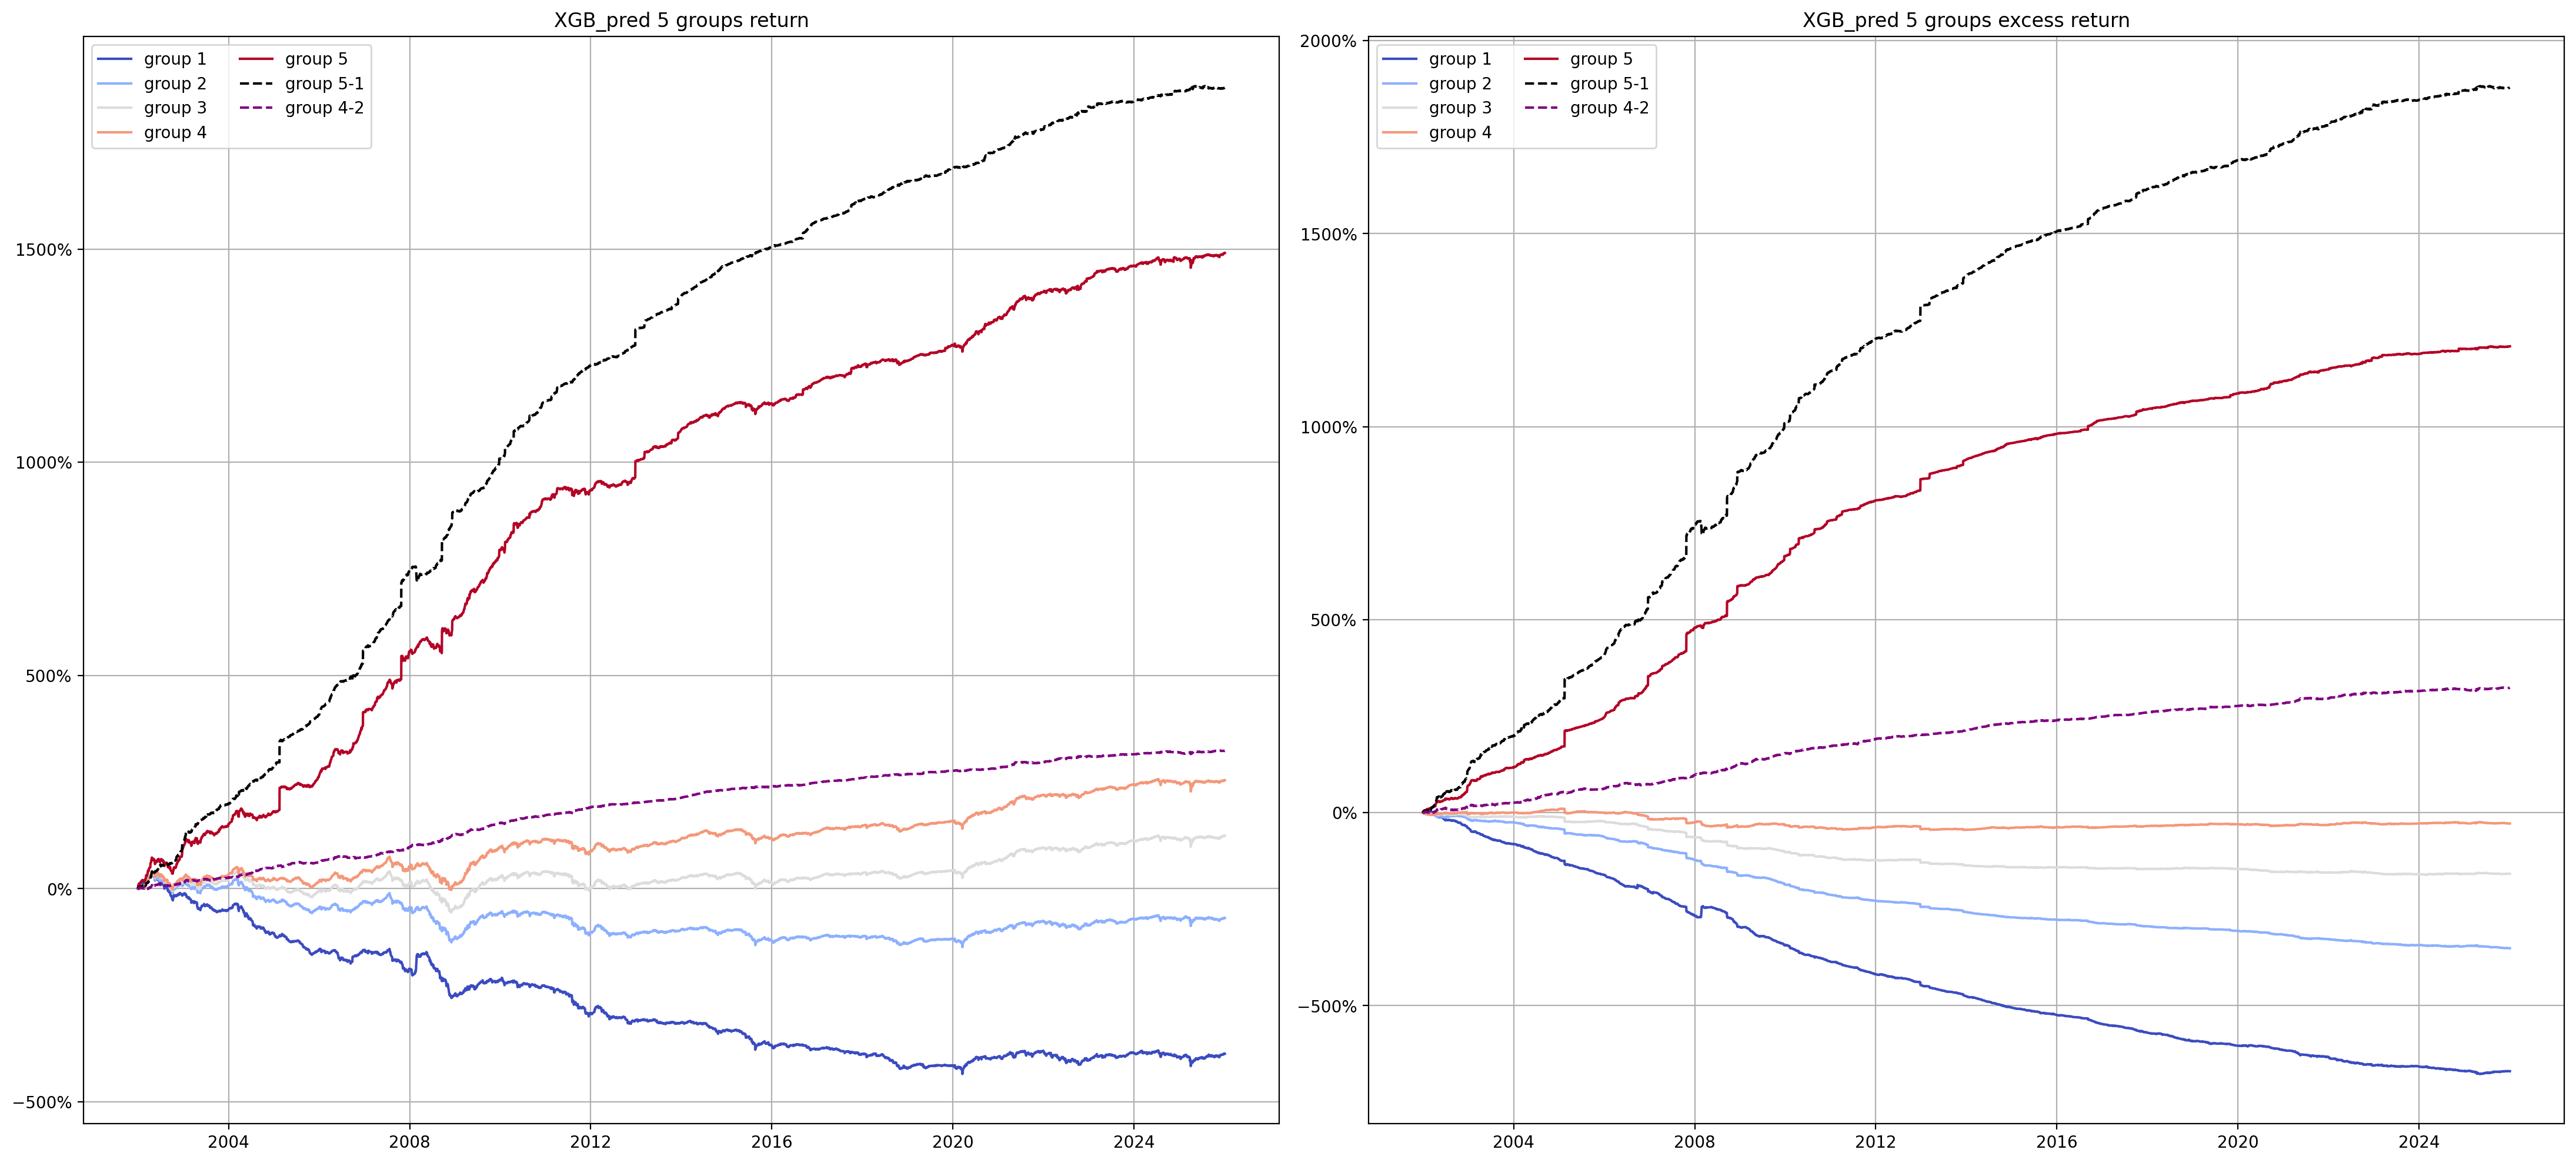

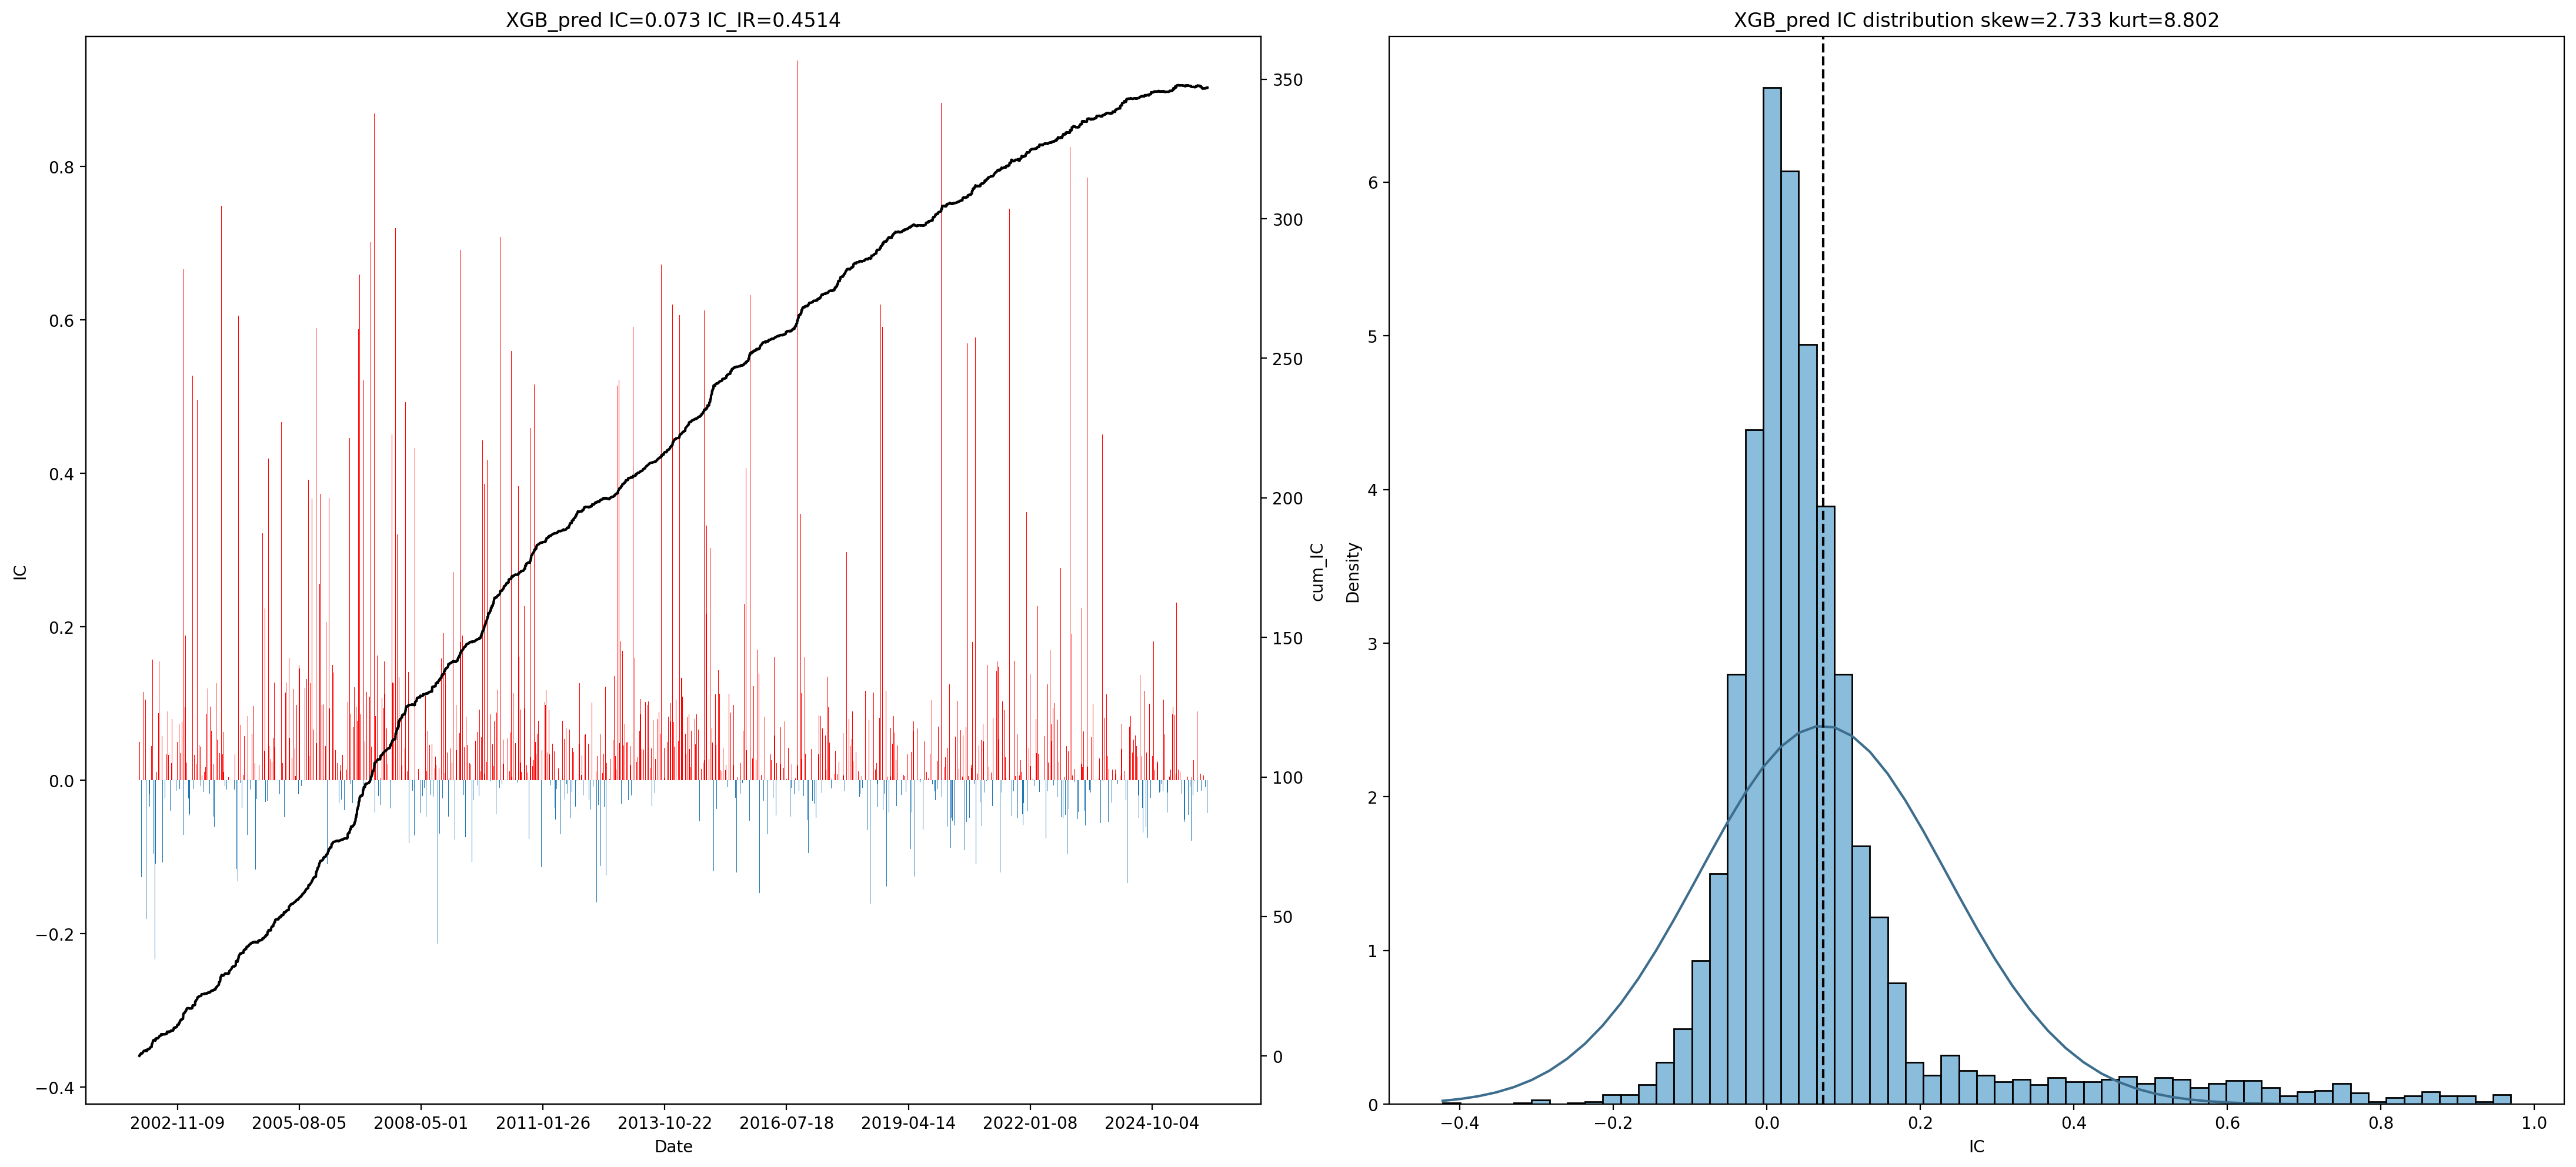

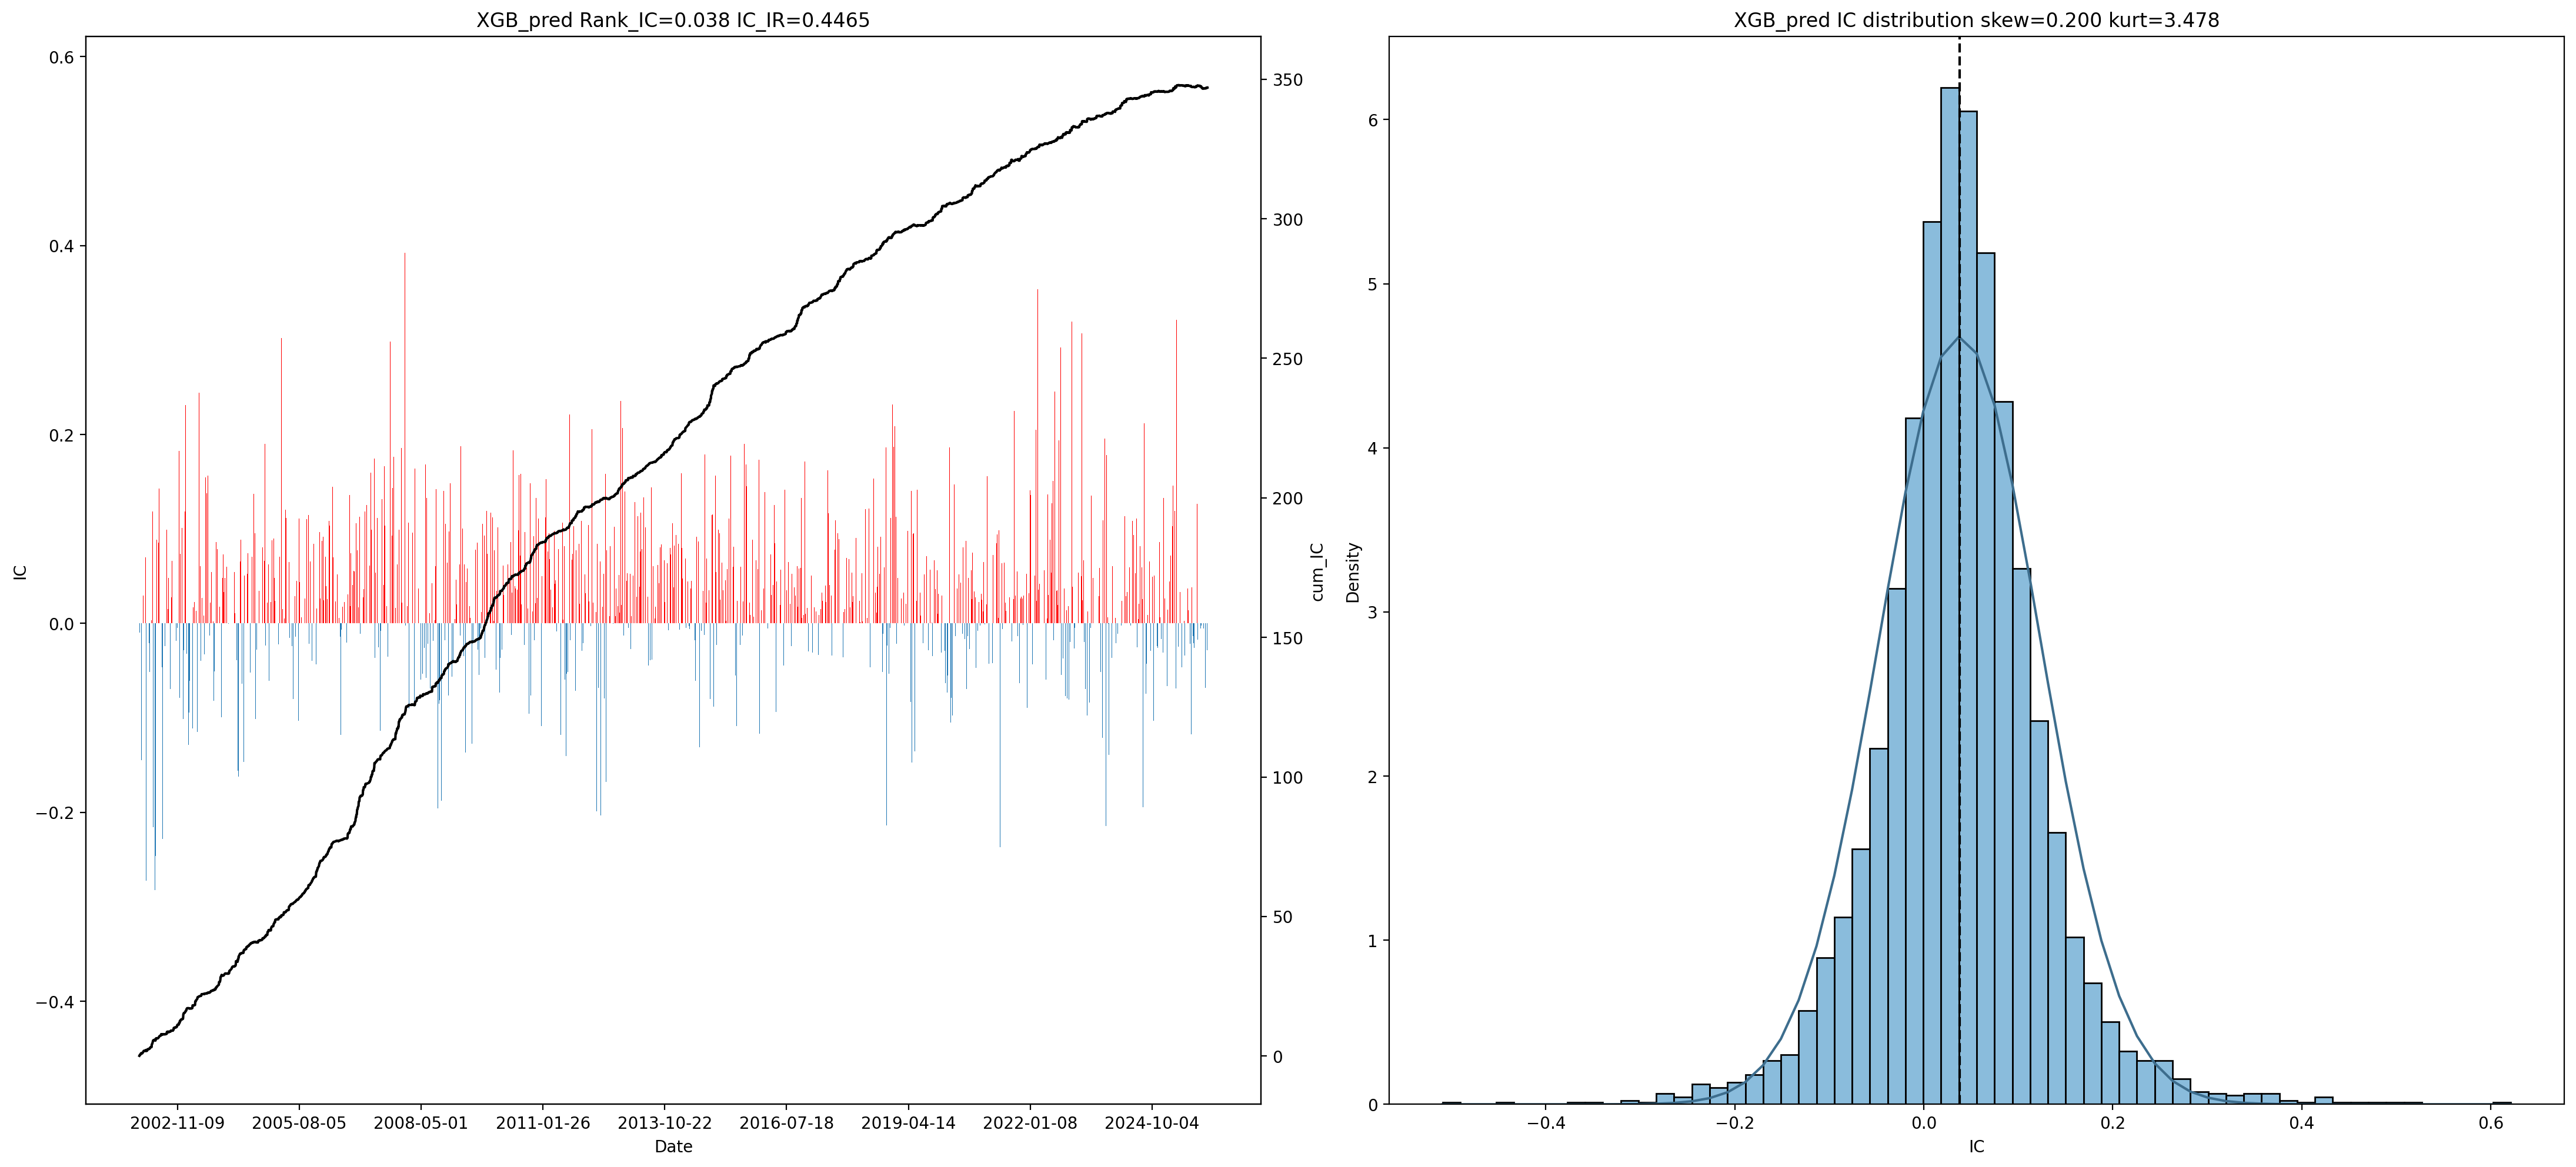

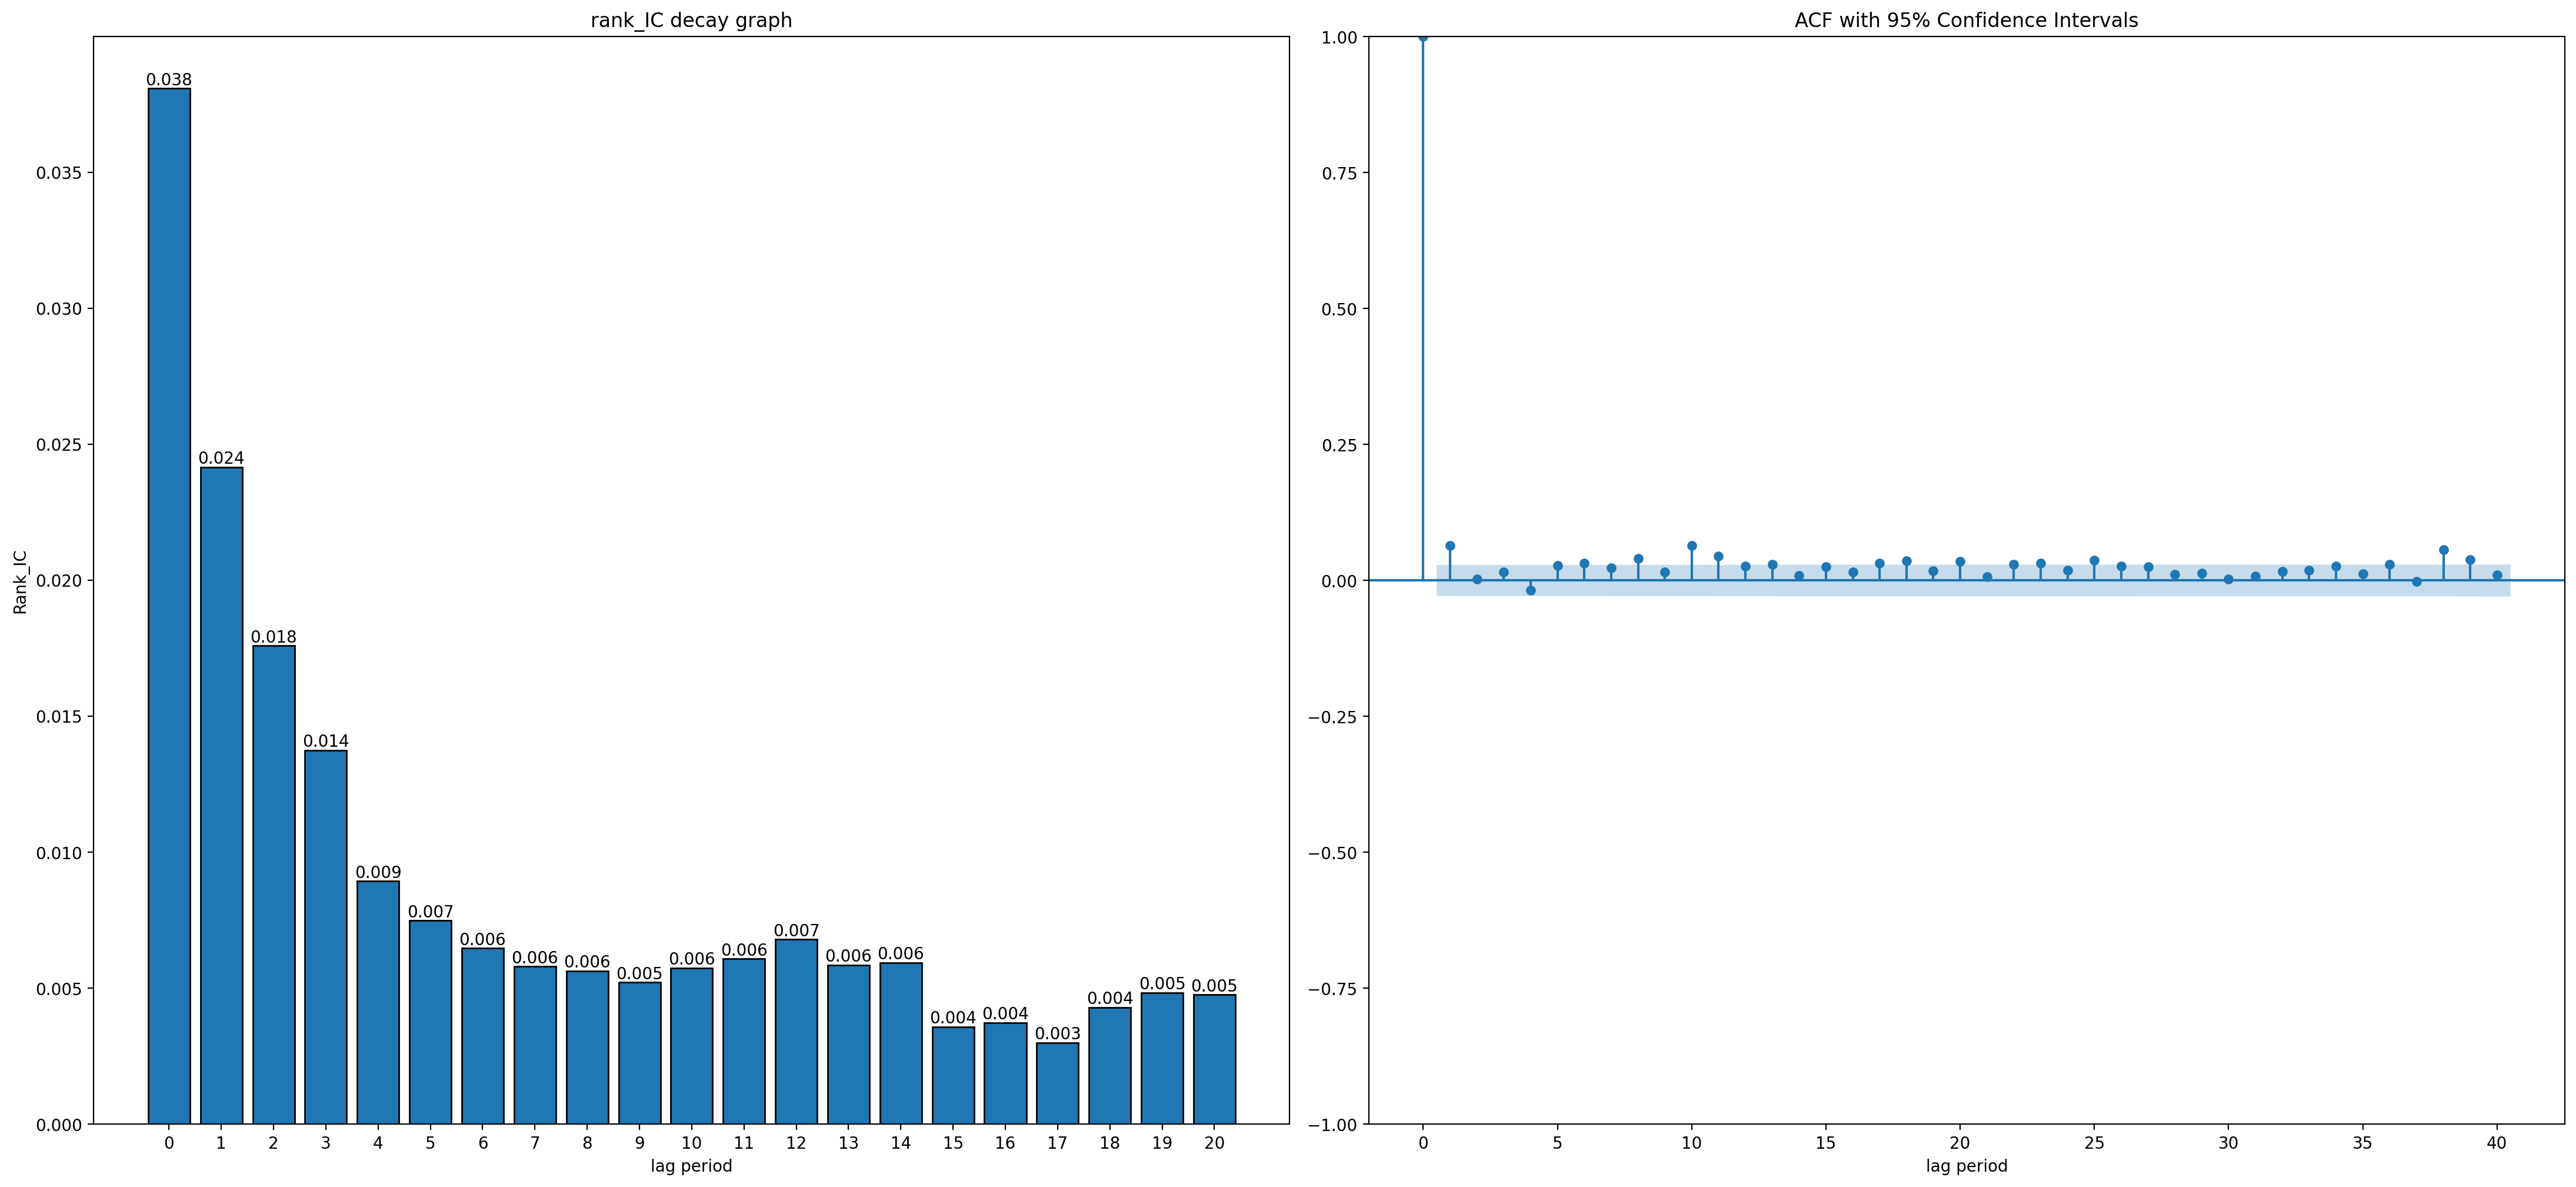

In [21]:
alpha.draw_pct()
alpha.draw_ic()
alpha.draw_ic(1)
alpha.draw_ic_dacay()

In [22]:
process_end_time = time()
print(f"Process time: {process_end_time - process_start_time:.2f} seconds")

Process time: 6332.06 seconds
